# Monte Carlo VaR of the book

How much can the book lose by tomorrow? This notebook answers with a Monte Carlo
**Value at Risk** (VaR) and **Expected Shortfall** (ES) on the three APOs of the example book,
**unhedged**: the options alone, no futures.

The engine is the same as the Monte Carlo pricer (see `src/cmdty/models/MONTE_CARLO.md`):

| | pricing | VaR |
|---|---|---|
| horizon | until the last fixing | 1 day (then 10) |
| simulated | the legs of one option | every risk factor of the book: HO, Brent, WTI |
| end of a scenario | the payoff | the whole book repriced |
| aggregate | the mean | the tail of the P&L |

1. Cholesky: from independent shocks to correlated ones
2. 10 000 scenarios for tomorrow
3. Full revaluation: P&L distribution, VaR and ES
4. VaR is not additive: trade by trade vs book
5. Shortcuts: delta and delta-gamma vs full revaluation
6. From 1 day to 10 days
7. Limits

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import QuantLib as ql

from cmdty import MarketData, Pricer, Quote, load_portfolio
from cmdty.market import any_exchange_calendar
from cmdty.models.montecarlo import cholesky_factor
from cmdty.plotting import MUTED, SERIES, ref_vline, titles, use_style
from cmdty.risk import book_greeks, book_risk, book_theta

use_style()

start = MarketData(
    today=ql.Date(10, 11, 2026), rate=0.04,
    quotes={"HO": Quote(105.0, 0.30), "BRENT": Quote(75.0, 0.32), "WTI": Quote(71.0, 0.33)},
    correlations={("HO", "BRENT"): 0.95, ("WTI", "BRENT"): 0.97, ("HO", "WTI"): 0.93},
)
book = load_portfolio("../portfolios/example_book.yaml")
pricer = Pricer(model="kirk", market=start)
today = book_risk(book, pricer)

pd.DataFrame({"PV today $": today.pv_by_trade}).round(0)

,PV today $
APO-001,51013.0
APO-002,-22536.0
APO-003,-65367.0


The book on 10 Nov 2026: a bought Brent put (January), a sold WTI−Brent put (April) and a
sold HO−Brent call (June). Its deltas, in bbl:

In [2]:
pd.Series(today.deltas, name="delta bbl").round(0).to_frame()

,delta bbl
BRENT,-4653.0
WTI,7341.0
HO,-10443.0


## 1. Cholesky: from independent shocks to correlated ones

The computer draws **independent** normals $Z$. The market needs **correlated** shocks $X$.
Cholesky splits the correlation matrix into $C = L L^\top$, with $L$ lower triangular, and

$$
X = L Z
$$

has exactly the correlation $C$, because $\mathrm{Cov}(LZ) = L\, I\, L^\top = C$.

- $Z$: raw randomness, one independent draw per underlying
- $L$: the recipe, how much of each $Z$ goes into each underlying. Computed **once**
- $X$: correlated shocks, ready for the SDEs

In [3]:
underlyings = ["HO", "BRENT", "WTI"]
C = np.array([[start.corr(a, b) for b in underlyings] for a in underlyings])
L = cholesky_factor(C)
pd.DataFrame(L, index=underlyings, columns=["z1", "z2", "z3"]).round(3)

,z1,z2,z3
HO,1.00,0.000,0.000
BRENT,0.95,0.312,0.000
WTI,0.93,0.277,0.242


Read it row by row:

- HO = 100% of $z_1$
- Brent = 0.95 of $z_1$ (the common shock) + 0.31 of $z_2$ (its own)
- WTI = mostly $z_1$, a bit of $z_2$, a little of its own $z_3$

Each row has squares summing to 1, so every $x$ is still $\mathcal{N}(0, 1)$: only the
correlation changed.

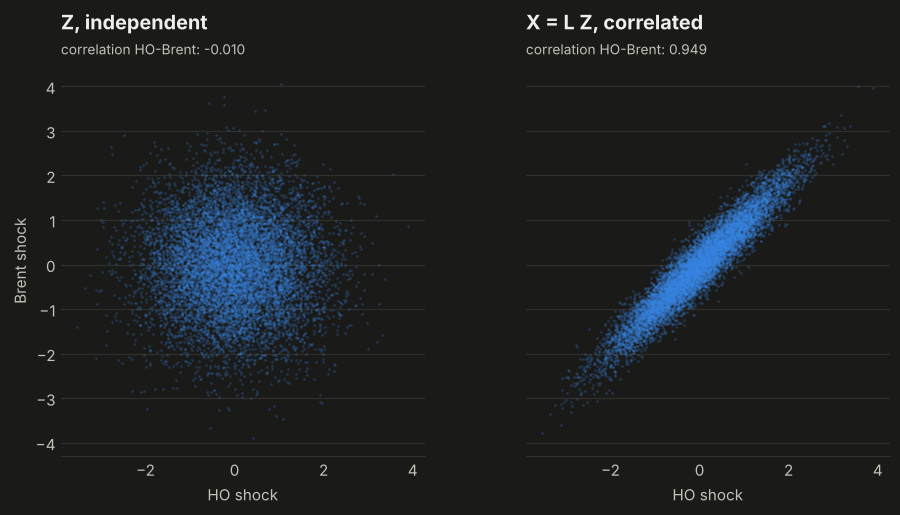

In [4]:
n = 10_000
rng = np.random.default_rng(7)
Z = rng.standard_normal((n, 3))
X = Z @ L.T

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, data, name in ((axes[0], Z, "Z, independent"), (axes[1], X, "X = L Z, correlated")):
    ax.set_axisbelow(True)
    ax.scatter(data[:, 0], data[:, 1], s=3, alpha=0.25, color=SERIES[0], linewidths=0)
    ax.set(xlabel="HO shock", aspect="equal")
    titles(ax, name, f"correlation HO-Brent: {np.corrcoef(data[:, 0], data[:, 1])[0, 1]:.3f}")
axes[0].set(ylabel="Brent shock")
plt.show()

Same 10 000 draws: a round cloud before, a thin tilted ellipse after. The correlation comes
back at 0.95 as set.

## 2. 10 000 scenarios for tomorrow

Each shock goes into its own SDE, here the driftless GBM used everywhere in the repo, with one
step of one day:

$$
F_u(t + \Delta t) = F_u(t)\, \exp\big(-\tfrac12\sigma_u^2 \Delta t + \sigma_u \sqrt{\Delta t}\; x_u\big)
$$

- $\sigma_u$: the implied vol of each underlying (constant)
- $\Delta t$: 10 Nov to 11 Nov, $1/365$ year (Actual/365, the convention of the pricer)
- one step is exact for the GBM, whatever $\Delta t$

In [5]:
def scenarios(x, start, horizon):
    """Prices of every underlying at the horizon, one row per scenario."""
    dt = ql.Actual365Fixed().yearFraction(start.today, horizon)
    vol = np.array([start.vol(u) for u in underlyings])
    f0 = np.array([start.forward(u) for u in underlyings])
    prices = f0 * np.exp(-0.5 * vol**2 * dt + vol * np.sqrt(dt) * x)
    return pd.DataFrame(prices, columns=underlyings)

tomorrow = ql.Date(11, 11, 2026)
prices = scenarios(X, start, tomorrow)
moves = prices - [start.forward(u) for u in underlyings]
moves.describe().loc[["mean", "std", "min", "max"]].round(2)

,HO,BRENT,WTI
mean,-0.01,-0.01,-0.01
std,1.63,1.24,1.21
min,-5.67,-4.62,-4.43
max,6.61,5.20,5.19


A typical day moves HO by about 1.6 $ and Brent by about 1.3 $, always mostly in the same
direction.

## 3. Full revaluation

In every scenario the **whole book is repriced** (Kirk, as the desk does), on tomorrow's date:

$$
\text{P\&L} = \text{PV}(\text{tomorrow, scenario}) - \text{PV}(\text{today})
$$

Then the 10 000 P&L are sorted:

- **VaR 99%**: the loss not exceeded on 99 days out of 100, i.e. minus the 1st percentile
- **ES 99%**: the average loss on the days beyond the VaR

In [6]:
def revalue(prices, start, horizon, pricer, book, pv_today):
    """P&L of each trade in each scenario: full revaluation on the horizon date."""
    rows = []
    for _, row in prices.iterrows():
        quotes = {u: Quote(row[u], start.vol(u)) for u in underlyings}
        market = start.model_copy(update={"today": horizon, "quotes": quotes})
        p = pricer.with_market(market)
        rows.append({t.id: t.instrument.quantity * p.pv(t.instrument) - pv_today[t.id]
                     for t in book})
    return pd.DataFrame(rows)

pnl_trades = revalue(prices, start, tomorrow, pricer, book, today.pv_by_trade)
pnl = pnl_trades.sum(axis=1)

def var(p, level):
    return -np.quantile(p, 1 - level)

def es(p, level):
    return -p[p <= -var(p, level)].mean()

summary = pd.DataFrame({
    "VaR $": {f"{l:.0%}": var(pnl, l) for l in (0.95, 0.99)},
    "ES $": {f"{l:.0%}": es(pnl, l) for l in (0.95, 0.99)},
})
summary.round(0)

,VaR $,ES $
95%,23277.0,28980.0
99%,32887.0,37168.0


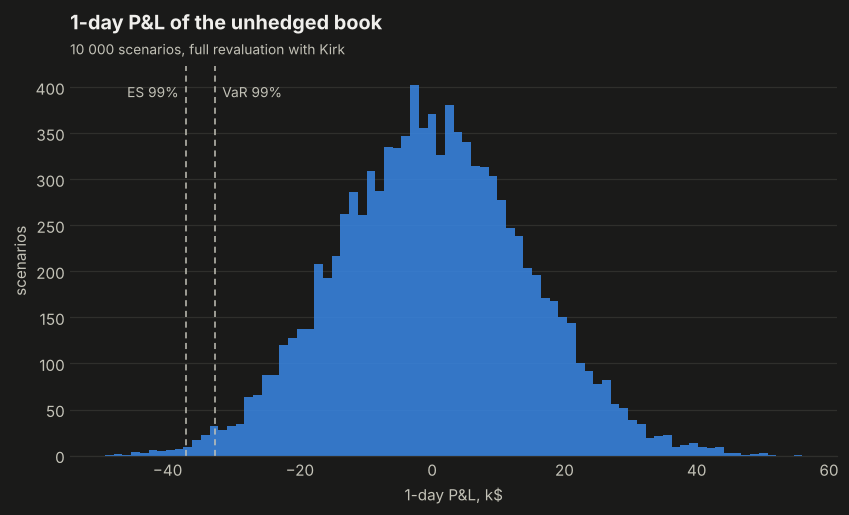

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.set_axisbelow(True)
ax.hist(pnl / 1e3, bins=80, color=SERIES[0], alpha=0.85)
for x, label, side in ((-var(pnl, 0.99) / 1e3, "VaR 99%", "left"),
                       (-es(pnl, 0.99) / 1e3, "ES 99%", "right")):
    ax.axvline(x, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.annotate(label, xy=(x, 0.92), xycoords=("data", "axes fraction"),
                xytext=(5 if side == "left" else -5, 0), textcoords="offset points",
                ha=side, color=MUTED, fontsize=9)
ax.set(xlabel="1-day P&L, k$", ylabel="scenarios")
titles(ax, "1-day P&L of the unhedged book", "10 000 scenarios, full revaluation with Kirk")
plt.show()

How to say it: *"on 99 days out of 100, the book does not lose more than the VaR by tomorrow;
on the remaining day, it loses the ES on average"*. The ES is always further out, it looks
inside the tail instead of stopping at its edge.

The book loses when prices **rise**: it is net short (HO −10.4k bbl and Brent −4.7k against
WTI +7.3k), and HO, the most expensive barrel, moves the most in dollars. With every price
moving together, the WTI long only partly offsets the shorts.

## 4. VaR is not additive

The same scenarios, trade by trade. Each trade's **standalone** VaR is computed on its own
P&L; the **book** VaR on the sum.

In [8]:
level = 0.99
standalone = pnl_trades.apply(lambda s: var(s, level))
tail = pnl <= -var(pnl, level)
contribution = -pnl_trades[tail].mean()  # share of the book ES carried by each trade

table = pd.DataFrame({"standalone VaR 99% $": standalone,
                      "contribution to ES 99% $": contribution})
table.loc["sum"] = table.sum()
table.loc["book"] = [var(pnl, level), es(pnl, level)]
table.round(0)

,standalone VaR 99% $,contribution to ES 99% $
APO-001,17815.0,17739.0
APO-002,5912.0,2814.0
APO-003,16757.0,16616.0
sum,40485.0,37168.0
book,32887.0,37168.0


- The **sum of standalone VaRs** is far above the book VaR: the trades hedge each other
  (Brent appears with opposite signs, and everything is correlated). Adding VaRs would
  overstate the risk. Averaging them would mean nothing.
- VaR is not even always *sub-additive* (in some books VaR(A + B) > VaR(A) + VaR(B)).
  ES always is: it is a *coherent* risk measure, one reason regulators moved to it.
- To say **who** carries the risk, use **contributions** computed on the same scenarios:
  each trade's average P&L in the book's tail scenarios. They add up exactly to the book ES.
  A negative contribution means the trade *gains* when the book loses: it is a hedge.

## 5. Shortcuts: delta and delta-gamma

Repricing every trade 10 000 times is the expensive part. Two classic shortcuts use the greeks
computed once today (plus the theta of one day):

$$
\text{delta: } \sum_u \Delta_u\, dF_u
\qquad
\text{delta-gamma: } \sum_u \Delta_u\, dF_u + \tfrac12 \sum_{a,b} \Gamma_{ab}\, dF_a\, dF_b
$$

And the **parametric** (delta-normal) VaR needs no simulation at all: with $\Sigma$ the covariance
of the daily dollar moves, $\text{VaR}_{99} = 2.33 \sqrt{\Delta^\top \Sigma\, \Delta}$.

In [9]:
greeks = book_greeks(book, pricer)
theta = book_theta(book, pricer, tomorrow)
delta = np.array([today.deltas.get(u, 0.0) for u in underlyings])

pnl_delta = moves.values @ delta + theta
pnl_dg = pnl_delta + np.array([greeks.gamma_pnl(dict(zip(underlyings, m))) for m in moves.values])

dt = ql.Actual365Fixed().yearFraction(start.today, tomorrow)
sd = np.array([start.forward(u) * start.vol(u) * np.sqrt(dt) for u in underlyings])  # $ per day
cov = np.outer(sd, sd) * C
parametric = 2.326 * np.sqrt(delta @ cov @ delta) - theta

pd.DataFrame({
    "VaR 99% $": {"full revaluation": var(pnl, 0.99), "delta-gamma": var(pnl_dg, 0.99),
                  "delta": var(pnl_delta, 0.99), "parametric (delta-normal)": parametric},
}).round(0)

,VaR 99% $
full revaluation,32887.0
delta-gamma,32871.0
delta,34321.0
parametric (delta-normal),34220.0


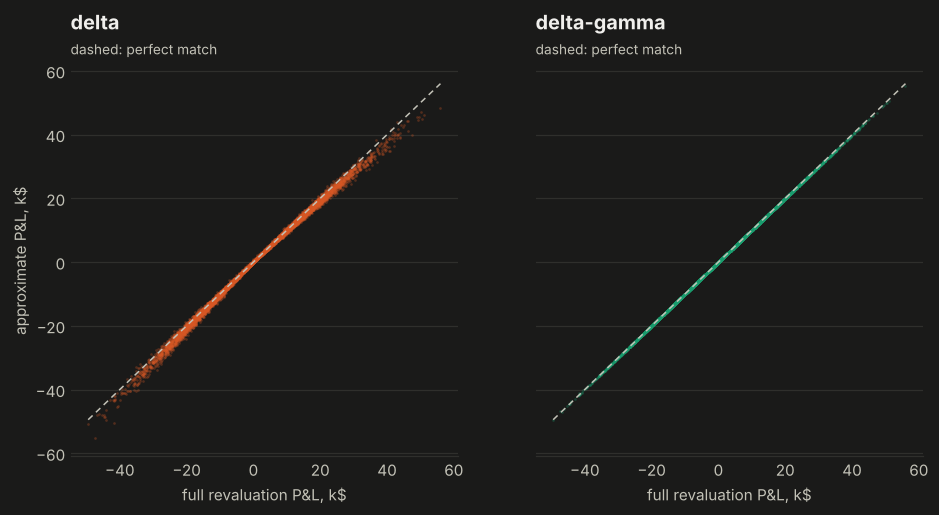

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, approx, name, color in ((axes[0], pnl_delta, "delta", SERIES[1]),
                                (axes[1], pnl_dg, "delta-gamma", SERIES[2])):
    ax.set_axisbelow(True)
    ax.scatter(pnl / 1e3, approx / 1e3, s=3, alpha=0.3, color=color, linewidths=0)
    lim = [pnl.min() / 1e3, pnl.max() / 1e3]
    ax.plot(lim, lim, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.set(xlabel="full revaluation P&L, k$")
    titles(ax, name, "dashed: perfect match")
axes[0].set(ylabel="approximate P&L, k$")
plt.show()

On one day, all methods agree closely: the moves are small and the book is close to linear.
The parametric VaR lands on the delta one: same linear book, formula instead of simulation.

The delta points bend at both ends, and here the delta slightly **overstates** the loss. The two
sold spread options are short gamma, but on the *spread*, which barely moves when all prices
move together. Along that common move, the bought Brent put's long gamma and the positive
cross-gammas win: the book is slightly convex in the direction that matters, so a big move
costs a bit less than the delta says. Adding the gamma term puts the points back on the line.
With a different book (sold outright options) the bend goes the other way, and delta
*understates* the loss: the dangerous case.

On a book with options close to expiry or a longer horizon, the gap grows, which is why risk
systems revalue in full or at least add gamma.

## 6. From 1 day to 10 days

Two ways:

- the shortcut: 1-day VaR $\times \sqrt{10}$, assuming independent days and a linear book
- the direct way: one step of 10 business days ($\Delta t$ = 14 calendar days / 365, exact for
  the GBM), with the book repriced **on the horizon date**, so ten days of time value are gone

In [11]:
calendar = any_exchange_calendar(["NYMEX", "ICE-EU"])
horizon10 = calendar.advance(start.today, ql.Period(10, ql.Days))
prices10 = scenarios(X, start, horizon10)
pnl10 = revalue(prices10, start, horizon10, pricer, book, today.pv_by_trade).sum(axis=1)

pd.DataFrame({
    "VaR 99% $": {"1 day": var(pnl, 0.99), "1 day x sqrt(10)": var(pnl, 0.99) * np.sqrt(10),
                  f"10 days (to {horizon10.ISO()})": var(pnl10, 0.99)},
    "ES 99% $": {"1 day": es(pnl, 0.99), "1 day x sqrt(10)": es(pnl, 0.99) * np.sqrt(10),
                 f"10 days (to {horizon10.ISO()})": es(pnl10, 0.99)},
}).round(0)

,VaR 99% $,ES 99% $
1 day,32887.0,37168.0
1 day x sqrt(10),103998.0,117537.0
10 days (to 2026-11-24),118872.0,137222.0


The direct 10-day number is higher than the scaled one, mostly for a reason of calendar:

- **calendar days vs trading days**: 10 business days are 14 calendar days here (two weekends),
  and the vols are per calendar year in this repo. Scaled by $\sqrt{14}$ instead, the 1-day VaR
  gives about 123k $, close to the direct run
- the rest comes from terms that do not scale like $\sqrt{t}$: theta (the book loses about
  4.7k $ of time value over the period) and gamma (bigger moves, more curvature)

The square-root rule is a convention, accepted because it is simple; the direct run is what the
model actually says.

## 7. Limits

- **Normal shocks**: real daily moves have fatter tails, so the 99% VaR is likely too low.
  Historical VaR (replay real past moves) or Student-t shocks would fix that.
- **Implied vols, not historical**: risk usually simulates with "real-world" vols and
  correlations estimated on recent history.
- **Vols do not move**: the vega risk (about +4.6k $ per vol point on Brent, −5.9k $ on HO)
  is not in the VaR. Adding the vols as risk factors, with their own shocks correlated to the
  prices, would bring it in.
- **One forward per underlying**: no curve, so no risk between contract months.
- **Unhedged**: the desk holds futures against these options. Their effect is the next step.